# 🌍 Data Visualization — Real-World Scenario Worksheet
### You are the analyst. Each task is a real situation with a *decision* at the end.

> **How this works**
> - Every task gives you a scenario, real-ish data, and a **question to answer with a chart**.
> - Don't just draw the chart — **pick the right one** and, in a comment, say what it tells you.
> - Fill in the `# YOUR CODE HERE` sections. Run each cell to check your output.
> - 🏆 Each task ends with a **"So what?"** — one sentence stating the insight, like a real analyst would tell their boss.


## ⚙️ Setup — Run This First

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
%matplotlib inline
sns.set_style('whitegrid')

---
## ☕ Task 1 — The Coffee Shop Owner

**Scenario:** You run a small coffee shop. You want to know **which days are busiest** so you can schedule more staff. Here are last week's cup sales.

**Your job:** Draw the chart that best compares days, and **highlight the two busiest days in a different colour** so the owner sees them instantly.

*(Hint: comparing categories → bar chart. To highlight, build a list of colours.)*

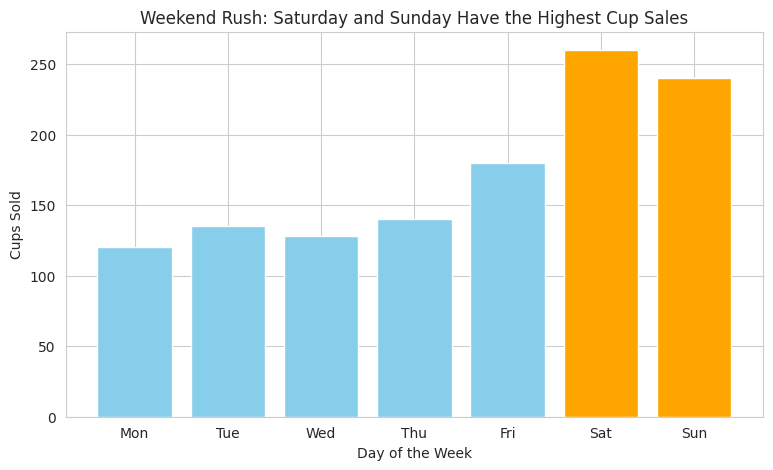

In [ ]:
days  = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
cups  = [120, 135, 128, 140, 180, 260, 240]

# YOUR CODE HERE
# 1. Bar chart of cups per day
# 2. Colour Sat & Sun differently from weekdays
# 3. Add a title that states the insight, plus axis labels

# 🏆 So what? (write one sentence as a comment)
# The busiest days are ____ , so the owner should ____ .

colors = ['skyblue' if day not in ['Sat', 'Sun'] else 'orange' for day in days]

plt.figure(figsize=(9, 5))
plt.bar(days, cups, color=colors)

# 3. Add a title that states the insight, plus axis labels
plt.title('Weekend Rush: Saturday and Sunday Have the Highest Cup Sales')
plt.xlabel('Day of the Week')
plt.ylabel('Cups Sold')

plt.show()

# 🏆 So what?
# The busiest days are Saturday and Sunday, so the owner should schedule more staff on weekends.

---
## 🏃 Task 2 — The Fitness Tracker

**Scenario:** Your fitness app records daily steps. Your goal is **8,000 steps/day**. You want to see **which days you hit the goal and which you missed.**

**Your job:** Draw a line plot of steps over the week, then add a **horizontal goal line at 8,000** so misses are obvious at a glance.

*(Hint: change over time → line plot. Use `ax.axhline()` for the goal line.)*

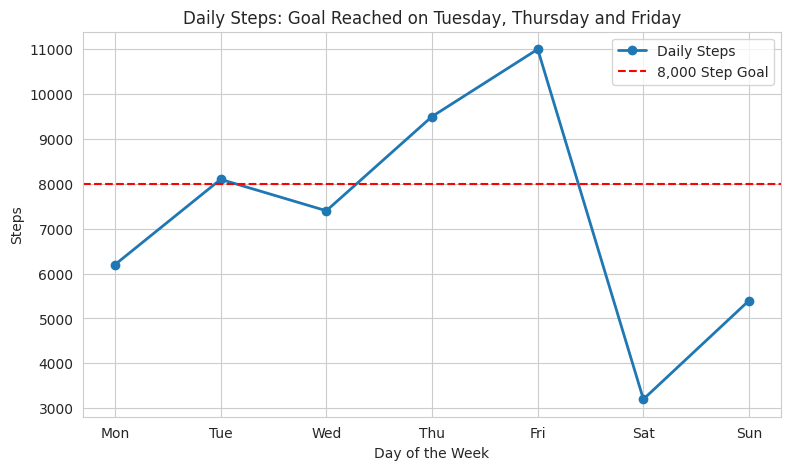

In [ ]:
days  = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
steps = [6200, 8100, 7400, 9500, 11000, 3200, 5400]

# YOUR CODE HERE
# 1. Line plot of steps with markers
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(days, steps, marker='o', linewidth=2, label='Daily Steps')

# 2. Add a dashed red horizontal line at the 8000 goal (with a legend label)
ax.axhline(y=8000, color='red', linestyle='--', label='8,000 Step Goal')

# 3. Title + axis labels
ax.set_title('Daily Steps: Goal Reached on Tuesday, Thursday and Friday')
ax.set_xlabel('Day of the Week')
ax.set_ylabel('Steps')
ax.legend()

plt.show()

# 🏆 So what? On which days did you MISS the goal?

# I missed the 8,000-step goal on Monday, Wednesday, Saturday, and Sunday.

---
## 📱 Task 3 — The Streaming Report (Pick the Right Chart!)

**Scenario:** A streaming service wants to show **how many hours were watched per genre**. A junior designer made a **pie chart** — but there are 6 genres with similar values, so it's unreadable.

**Your job:** Prove the point. Draw the **pie chart (the bad version)** AND a **sorted horizontal bar chart (the good version)** side by side. Then, in a comment, say which one answers *"which genre is #1?"* faster.

*(Hint: `plt.subplots(1, 2)`. Sort the data before the bar chart.)*

In [ ]:
genres = ['Drama','Comedy','Action','Docs','Horror','Sci-Fi']
hours  = [42, 39, 36, 30, 28, 25]

# YOUR CODE HERE
# Left subplot: pie chart of the same data
axes[0].pie(hours, labels=genres, autopct='%1.1f%%', startangle=90)
axes[0].set_title('Pie Chart: Harder to Compare Similar Values')

# Right subplot: SORTED horizontal bar chart
sorted_data = sorted(zip(hours, genres))
sorted_hours, sorted_genres = zip(*sorted_data)

axes[1].barh(sorted_genres, sorted_hours)
axes[1].set_title('Sorted Bar Chart: Genre Ranking Is Clear')
axes[1].set_xlabel('Hours Watched')
axes[1].set_ylabel('Genre')

plt.tight_layout()
plt.show()

# 🏆 So what? Which chart makes the ranking obvious, and why?

# The sorted horizontal bar chart makes the ranking obvious because bar lengths
#are much easier to compare than similar-sized pie slices; Drama is #1.

---
## 🎓 Task 4 — Does Studying Actually Help? (Relationship)

**Scenario:** A school wants to know if **more study hours really lead to higher exam scores**, or if it's a myth.

**Your job:** Draw a **scatter plot** of study hours vs exam score. Then use Seaborn's `regplot` to add a **trend line** so the relationship is clear.

*(Hint: relationship between two numbers → scatter. `sns.regplot` adds the line for you.)*

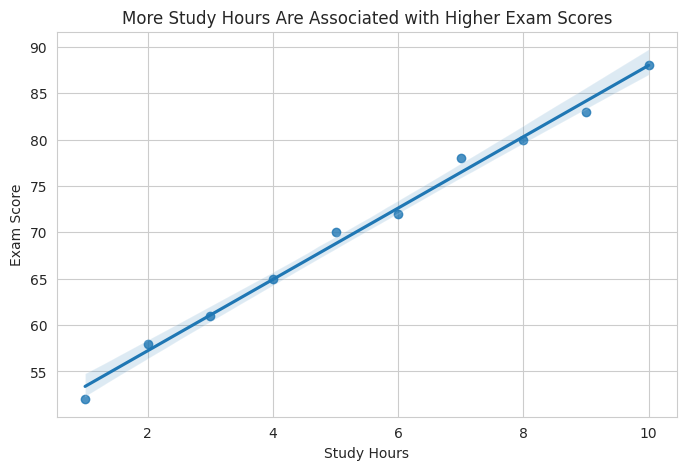

In [ ]:
study_hours = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
exam_score  = [52, 58, 61, 65, 70, 72, 78, 80, 83, 88]

# YOUR CODE HERE
# 1. sns.regplot of study_hours (x) vs exam_score (y)
plt.figure(figsize=(8, 5))
sns.regplot(x=study_hours, y=exam_score)

# 2. Title + axis labels
plt.title('More Study Hours Are Associated with Higher Exam Scores')
plt.xlabel('Study Hours')
plt.ylabel('Exam Score')

plt.show()

# 🏆 So what? Is the relationship positive, negative, or none?

# The relationship is positive: as study hours increase, exam scores generally increase.

---
## 🍽️ Task 5 — The Restaurant Manager (Seaborn EDA)

**Scenario:** You manage a restaurant and want to know **when customers tip best**, so you can schedule your best servers then. Use the built-in `tips` dataset.

**Your job:** Build a **heatmap of average tip by day and time (Lunch/Dinner)**. The brightest cell is your money slot.

*(Hint: `pivot_table` to get day × time → tip, then `sns.heatmap(..., annot=True)`.)*

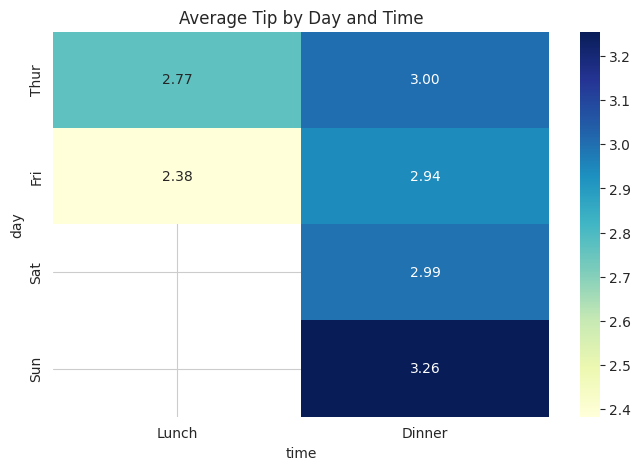

In [ ]:
tips = sns.load_dataset('tips')

# YOUR CODE HERE
# 1. Make a pivot_table: index='day', columns='time', values='tip', aggfunc='mean'
tip_table = tips.pivot_table(
    index='day',
    columns='time',
    values='tip',
    aggfunc='mean',
    observed=False
)

# 2. sns.heatmap of that table with annot=True and a colour map
plt.figure(figsize=(8, 5))
sns.heatmap(tip_table, annot=True, fmt='.2f', cmap='YlGnBu')

# 3. Title
plt.title('Average Tip by Day and Time')

plt.show()

# 🏆 So what? Which day + time has the highest average tip?

# Sunday dinner has the highest average tip, so this is the strongest time slot for tipping.

---
## 📈 Task 6 — The Startup Pitch (Interactive Plotly)

**Scenario:** You're pitching investors and want an **interactive** chart they can hover over. Using the `gapminder` dataset, show **how life expectancy relates to income**, and let them **watch it change over the years.**

**Your job:** Build a Plotly **animated scatter plot**: `gdpPercap` (x, log scale) vs `lifeExp` (y), bubble size = population, colour = continent, animation frame = year.

*(Hint: `px.scatter(..., animation_frame='year', log_x=True, size='pop', color='continent')`.)*

In [ ]:
gapminder = px.data.gapminder()

# YOUR CODE HERE — one px.scatter call with animation_frame='year'
# Remember: log_x=True, size='pop', color='continent', hover_name='country'
fig = px.scatter(
    gapminder,
    x='gdpPercap',
    y='lifeExp',
    animation_frame='year',
    size='pop',
    color='continent',
    hover_name='country',
    log_x=True,
    size_max=60,
    title='Life Expectancy vs Income Over Time'
)

fig.show()

# 🏆 So what? What overall trend do you see as the years play forward?

# As the years move forward, countries generally become richer and live longer,
#with higher GDP per person associated with higher life expectancy.

---
## 🛒 Task 7 — CAPSTONE: The E-Commerce Dashboard (Your Judgment)

**Scenario:** You're the data analyst for an online store. The founder asks for a **one-glance dashboard** of last week's performance. Below is the data.

**Your job:** Build a **2×2 dashboard** (`plt.subplots(2, 2)`). *You* choose the 4 charts — but you must pick the **right chart for each question** and write *why* in a comment above each.

Answer these 4 questions, one per subplot:
1. How did **daily revenue trend** across the week?
2. How do **orders compare** across days?
3. Is there a **relationship between orders and revenue**?
4. What **share of revenue** came from each product category? *(few categories → pie is OK here)*


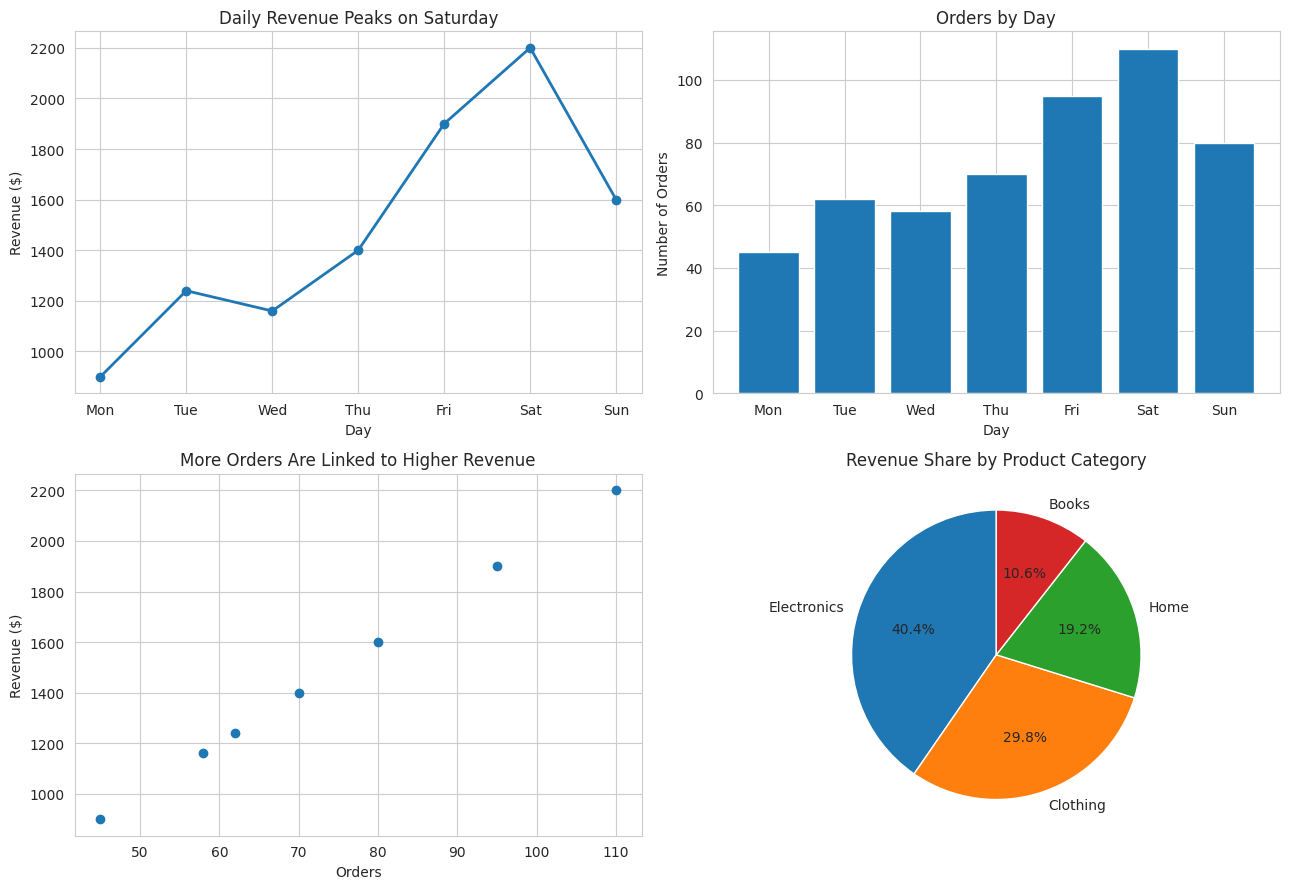

In [ ]:
df = pd.DataFrame({
    'Day':      ['Mon','Tue','Wed','Thu','Fri','Sat','Sun'],
    'Orders':   [45,   62,   58,   70,   95,  110,   80 ],
    'Revenue':  [900, 1240, 1160, 1400, 1900, 2200, 1600],
})
cat_names  = ['Electronics','Clothing','Home','Books']
cat_revenue= [4200, 3100, 2000, 1100]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (0,0) Chart type chosen: ____ Line chart  | Why: ____ A line chart is best for showing how revenue changes over time.
# YOUR CODE HERE
axes[0, 0].plot(df['Day'], df['Revenue'], marker='o', linewidth=2)
axes[0, 0].set_title('Daily Revenue Peaks on Saturday')
axes[0, 0].set_xlabel('Day')
axes[0, 0].set_ylabel('Revenue ($)')

# (0,1) Chart type chosen: ____ Bar chart  | Why: ____ A bar chart makes it easy to compare order counts across separate days.
# YOUR CODE HERE
axes[0, 1].bar(df['Day'], df['Orders'])
axes[0, 1].set_title('Orders by Day')
axes[0, 1].set_xlabel('Day')
axes[0, 1].set_ylabel('Number of Orders')

# (1,0) Chart type chosen: ____ Scatter plot   | Why: ____ A scatter plot shows the relationship between two numerical variables.
# YOUR CODE HERE
axes[1, 0].scatter(df['Orders'], df['Revenue'])
axes[1, 0].set_title('More Orders Are Linked to Higher Revenue')
axes[1, 0].set_xlabel('Orders')
axes[1, 0].set_ylabel('Revenue ($)')

# (1,1) Chart type chosen: ____ Pie chart  | Why: ____ There are only four categories, so a pie chart clearly shows each category's share of revenue.
# YOUR CODE HERE
axes[1, 1].pie(
    cat_revenue,
    labels=cat_names,
    autopct='%1.1f%%',
    startangle=90
)
axes[1, 1].set_title('Revenue Share by Product Category')


plt.tight_layout()
plt.show()

# 🏆 So what? Write 2 sentences the founder should take away from this dashboard.

# Revenue and orders generally increased through the week and both peaked on Saturday, showing that higher order volume strongly drives revenue.
# Electronics generated the largest share of category revenue, so the founder
#should prioritize the weekend sales period and the strongest-performing category.

---
## 🤔 Wrap-Up Reflection
Answer as comments in the cell below.
1. For each task, did the *question* point you to the chart before you looked at the data? That's the skill.
2. In Task 3, why did the sorted bar chart beat the pie chart?
3. Name one chart from this worksheet where **starting the y-axis at zero** matters, and one where it doesn't.
4. In the capstone, which of your 4 charts was hardest to choose, and why?


In [ ]:
# Q1: Yes. The type of question pointed to the chart choice before looking at the values:
# comparisons suggested bar charts, trends over time suggested line charts,
# relationships suggested scatter plots, and part-to-whole questions suggested pie charts.

# Q2: The sorted bar chart beat the pie chart because the bar lengths are easier to compare
# and the sorting makes the ranking immediately clear. It shows that Drama is #1 faster.

# Q3: Starting the y-axis at zero matters for the Task 1 bar chart because bar lengths represent
# magnitude and a non-zero baseline could exaggerate differences. It does not matter as much
# for the Task 4 scatter plot because the goal is to show the relationship between study hours
# and exam scores rather than compare bar lengths.

# Q4: The revenue-share chart was the hardest to choose because both a bar chart and pie chart
# could display the categories. I chose a pie chart because the question asks for each
# category's share of a total and there are only four categories, so the proportions stay readable.